# Session 1: Inspect the improved sample dataset (v2)

All commercial records and organisation/contact names are invented. Product labels use recognisable generic names; prices and pack combinations are illustrative. Quality issues are deliberately simulated.

Save this notebook to Drive. Run the next cell and upload **Pharma_2024_2025_Improved_Data_v2.zip**. Upload the ZIP itself, not individual CSV files.


In [ ]:
from google.colab import files
import pandas as pd
from io import BytesIO
from pathlib import PurePosixPath
from zipfile import ZipFile

uploaded = files.upload()
zip_files = [name for name in uploaded if name.lower().endswith('.zip')]
if len(zip_files) != 1:
    raise ValueError('Please upload exactly one file: the improved v2 dataset ZIP.')
expected = ['categories.csv', 'products.csv', 'customers.csv', 'suppliers.csv', 'batches.csv', 'stock_receipts.csv', 'sales.csv', 'stock_adjustments.csv', 'inventory_month_end.csv']
loaded_tables = {}
with ZipFile(BytesIO(uploaded[zip_files[0]])) as archive:
    for filename in expected:
        matches = [path for path in archive.namelist()
                   if 'raw_data' in PurePosixPath(path).parts
                   and PurePosixPath(path).name == filename]
        if len(matches) != 1:
            raise ValueError(f'Expected one raw_data/{filename}, found {len(matches)}. Use the complete v2 ZIP.')
        with archive.open(matches[0]) as csv_file:
            loaded_tables[filename[:-4]] = pd.read_csv(csv_file, dtype='string')
if 'pack_size_units' not in loaded_tables['products'].columns:
    raise ValueError('This looks like the older dataset. Please upload the improved v2 ZIP.')
tables = loaded_tables
print('Loaded', len(tables), 'tables — improved dataset v2')
print('Source: synthetic educational data, 2024–2025')


In [ ]:
print("Files received:")
for name in uploaded:
    print(repr(name))

Files received:
'batches (1).csv'
'categories (1).csv'
'customers (1).csv'
'inventory_month_end (1).csv'
'products (1).csv'
'sales (1).csv'
'stock_adjustments (1).csv'
'stock_receipts (1).csv'
'suppliers (1).csv'


## Inspect table sizes and fields


In [ ]:
summary = pd.DataFrame([{'table': name, 'rows': len(df), 'columns': len(df.columns), 'exact_duplicate_rows': int(df.duplicated().sum())} for name, df in tables.items()])
display(summary)
for name, df in tables.items():
    print('TABLE:', name)
    display(df.head(3))


,table,rows,columns,exact_duplicate_rows
0,categories,8,2,0
1,products,100,13,0
2,customers,40,7,0
3,suppliers,10,4,0
4,batches,1880,6,0
5,stock_receipts,1880,5,0
6,sales,49668,8,235
7,stock_adjustments,69,6,0
8,inventory_month_end,2400,3,0


TABLE: categories


,category_id,category_name
0,CAT01,Respiratory
1,CAT02,Digestive Care
2,CAT03,Cardiovascular


TABLE: products


,product_id,product_name,generic_name,strength,dosage_form,pack_size_units,category_id,manufacturer,unit_of_measure,standard_cost_inr,list_price_inr,reorder_point_packs,target_stock_packs
0,P001,Montelukast 5 mg Tablets - Pack of 10,Montelukast,5 mg,Tablet,10,CAT01,AARVION LIFE SCIENCES,pack,71.57,93.34,100,500
1,P002,Montelukast 5 mg Tablets - Pack of 20,Montelukast,5 mg,Tablet,20,CAT01,Aarvion Life Sciences,pack,137.01,191.16,80,320
2,P003,Montelukast 10 mg Tablets - Pack of 10,Montelukast,10 mg,Tablet,10,CAT01,Aarvion Life Sciences,pack,85.21,112.36,60,300


TABLE: customers


... (9 outputs left out)

TABLE: stock_adjustments


,adjustment_id,adjustment_date,product_id,batch_id,adjustment_type,quantity_change_packs
0,A000001,2024-02-08,P091,B000091,EXPIRY_WRITE_OFF,-357
1,A000002,2024-02-12,P065,B000065,EXPIRY_WRITE_OFF,-53
2,A000003,2024-02-17,P074,B000074,EXPIRY_WRITE_OFF,-80


TABLE: inventory_month_end


,snapshot_date,product_id,closing_stock_packs
0,2024-01-31,P001,471
1,2024-01-31,P002,161
2,2024-01-31,P003,253


## Inspect missing values

A missing customer is not a reason to discard a valid sale. Record what you find before choosing a treatment.


In [ ]:
for name, df in tables.items():
    counts = df.isna().sum()
    print(name)
    display(counts[counts > 0].to_frame('missing_count'))


categories


,missing_count


products


,missing_count


customers


,missing_count


... (8 outputs left out)

stock_adjustments


,missing_count


inventory_month_end


,missing_count


## Inspect the sales columns

Look for inconsistent date formats, formatted prices, product-key whitespace, and repeated sale-line IDs. Do not edit the source tables yet.


In [ ]:
sales = tables['sales']
print('Repeated sale-line IDs:', int(sales['sales_line_id'].duplicated().sum()))
display(sales[sales['sale_date'].str.contains('/', na=False)].head())
display(sales[sales['unit_price_inr'].str.contains('INR', na=False)].head())
display(sales[sales['product_id'] != sales['product_id'].str.strip().str.upper()].head())


Repeated sale-line IDs: 235


,sales_line_id,sale_date,customer_id,product_id,batch_id,quantity_packs,unit_price_inr,discount_pct
171,L0025274,15/01/2025,C033,P039,B000951,5,INR 65.35,5
222,L0002668,09/02/2024,C023,P011,B000011,4,28.59,10
747,L0027560,15/02/2025,C022,P068,B001004,5,26.7,0
778,L0038355,23/07/2025,C025,P083,B001407,2,11.86,5
849,L0018162,06/10/2024,C030,P016,B000696,12,102.01,0


,sales_line_id,sale_date,customer_id,product_id,batch_id,quantity_packs,unit_price_inr,discount_pct
41,L0048975,2025-12-25,C015,P092,B001854,16,INR 36.57,5
70,L0016105,2024-09-03,C005,P099,B000646,3,INR 31.46,0
95,L0020603,2024-11-11,C035,P013,B000787,30,INR 38.89,0
171,L0025274,15/01/2025,C033,P039,B000951,5,INR 65.35,5
190,L0041017,2025-09-02,C023,P076,B001561,2,INR 60.09,0


,sales_line_id,sale_date,customer_id,product_id,batch_id,quantity_packs,unit_price_inr,discount_pct
1109,L0009570,2024-05-21,C020,p078,B000399,6,96.54,0
1436,L0023124,2024-12-17,C017,p005,B000861,36,25.09,5
1551,L0043957,2025-10-16,C003,p028,B001476,4,52.57,10
1609,L0036427,2025-06-23,C016,p026,B001409,8,43.69,0
1641,L0030654,2025-03-30,C013,p034,B000948,2,83.21,5


In [ ]:
clean_tables = {
    name: df.copy(deep=True)
    for name, df in tables.items()
}

sales = clean_tables["sales"]

In [ ]:
print("Rows before cleaning:", len(sales))
print("Exact duplicate rows:", sales.duplicated().sum())

# Remove exact duplicates in a temporary copy for checking
unique_rows = sales.drop_duplicates()

conflicts = unique_rows[
    unique_rows.duplicated("sales_line_id", keep=False)
]

print("Conflicting rows with the same sale-line ID:", len(conflicts))
display(conflicts.head())

Rows before cleaning: 49668
Exact duplicate rows: 235
Conflicting rows with the same sale-line ID: 0


,sales_line_id,sale_date,customer_id,product_id,batch_id,quantity_packs,unit_price_inr,discount_pct


In [ ]:
before = len(clean_tables["sales"])

clean_tables["sales"] = (
    clean_tables["sales"]
    .drop_duplicates()
    .reset_index(drop=True)
)

sales = clean_tables["sales"]

cleaning_log = [{
    "table": "sales",
    "action": "Remove exact duplicate rows",
    "rows_before": before,
    "rows_after": len(sales),
    "rows_removed": before - len(sales)
}]

display(pd.DataFrame(cleaning_log))


,table,action,rows_before,rows_after,rows_removed
0,sales,Remove exact duplicate rows,49668,49433,235


In [ ]:
print("Sales rows after cleaning:", len(sales))
print("Repeated sale-line IDs:",
      sales["sales_line_id"].duplicated().sum())
print("Missing customer IDs:",
      sales["customer_id"].isna().sum())

Sales rows after cleaning: 49433
Repeated sale-line IDs: 0
Missing customer IDs: 161


In [ ]:
text_changes = []

for table_name, df in clean_tables.items():
    for column in df.columns:
        if column.endswith("_id"):
            before = df[column].copy()
            after = before.str.strip().str.upper()

            changed = (
                before.fillna("<MISSING>")
                != after.fillna("<MISSING>")
            ).sum()

            df[column] = after

            if changed:
                text_changes.append({
                    "table": table_name,
                    "column": column,
                    "action": "Trim spaces and uppercase identifiers",
                    "values_changed": int(changed)
                })

In [ ]:
text_rules = {
    "products": {
        "product_name": "strip",
        "manufacturer": "title"
    },
    "customers": {
        "city": "title"
    }
}

for table_name, rules in text_rules.items():
    df = clean_tables[table_name]

    for column, rule in rules.items():
        before = df[column].copy()
        after = before.str.strip()

        if rule == "title":
            after = after.str.title()

        changed = (
            before.fillna("<MISSING>")
            != after.fillna("<MISSING>")
        ).sum()

        df[column] = after

        text_changes.append({
            "table": table_name,
            "column": column,
            "action": f"Standardise text: {rule}",
            "values_changed": int(changed)
        })

cleaning_log.extend(text_changes)

display(pd.DataFrame(text_changes))

,table,column,action,values_changed
0,sales,product_id,Trim spaces and uppercase identifiers,197
1,products,product_name,Standardise text: strip,12
2,products,manufacturer,Standardise text: title,8
3,customers,city,Standardise text: title,6


In [ ]:
sales = clean_tables["sales"]

date_text = sales["sale_date"].str.strip()
slash_dates = date_text.str.contains("/", na=False)

parsed_dates = pd.Series(
    pd.NaT, index=sales.index, dtype="datetime64[ns]"
)

parsed_dates.loc[slash_dates] = pd.to_datetime(
    date_text.loc[slash_dates],
    format="%d/%m/%Y",
    errors="coerce"
)

parsed_dates.loc[~slash_dates] = pd.to_datetime(
    date_text.loc[~slash_dates],
    format="%Y-%m-%d",
    errors="coerce"
)

assert parsed_dates.notna().all(), "Some dates need investigation."

sales["sale_date"] = parsed_dates

print("Unparsed dates:", sales["sale_date"].isna().sum())
print("First date:", sales["sale_date"].min().date())
print("Last date:", sales["sale_date"].max().date())

Unparsed dates: 0
First date: 2024-01-01
Last date: 2025-12-31


In [ ]:
price_text = (
    sales["unit_price_inr"]
    .str.replace("INR", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

parsed_prices = pd.to_numeric(price_text, errors="coerce")

assert parsed_prices.notna().all(), "Some prices need investigation."
assert (parsed_prices > 0).all(), "Some prices are zero or negative."

sales["unit_price_inr"] = parsed_prices

cleaning_log.extend([
    {
        "table": "sales",
        "column": "sale_date",
        "action": "Parse ISO and day/month/year dates",
        "values_processed": len(sales)
    },
    {
        "table": "sales",
        "column": "unit_price_inr",
        "action": "Remove currency formatting and convert to numeric",
        "values_processed": len(sales)
    }
])

print("Invalid prices:", sales["unit_price_inr"].isna().sum())
print(sales[["sale_date", "unit_price_inr"]].dtypes)

Invalid prices: 0
sale_date         datetime64[ns]
unit_price_inr           Float64
dtype: object


In [ ]:
quantity = pd.to_numeric(
    sales["quantity_packs"], errors="coerce"
)

discount = pd.to_numeric(
    sales["discount_pct"], errors="coerce"
)

# Validate before saving the converted values
assert quantity.notna().all(), "Some quantities are missing or invalid."
assert (quantity > 0).all(), "Quantities must be positive."
assert (quantity % 1 == 0).all(), "Pack quantities must be whole numbers."

assert discount.notna().all(), "Some discounts are missing or invalid."
assert discount.between(0, 100).all(), "Discounts must be between 0 and 100."

sales["quantity_packs"] = quantity.astype("Int64")
sales["discount_pct"] = discount.astype("Float64")

cleaning_log.extend([
    {
        "table": "sales",
        "column": "quantity_packs",
        "action": "Convert to positive whole-number quantity",
        "values_processed": len(sales)
    },
    {
        "table": "sales",
        "column": "discount_pct",
        "action": "Convert to numeric and validate percentage range",
        "values_processed": len(sales)
    }
])

In [ ]:
print(sales[
    ["sale_date", "quantity_packs", "unit_price_inr", "discount_pct"]
].dtypes)

print("\nDate range:",
      sales["sale_date"].min().date(),
      "to",
      sales["sale_date"].max().date())

print("\nSales rows:", len(sales))

sale_date         datetime64[ns]
quantity_packs             Int64
unit_price_inr           Float64
discount_pct             Float64
dtype: object

Date range: 2024-01-01 to 2025-12-31

Sales rows: 49433


In [ ]:
missing_customers = sales["customer_id"].isna().sum()

sales["customer_id"] = sales["customer_id"].fillna("C_UNKNOWN")

customers = clean_tables["customers"]

if "C_UNKNOWN" not in customers["customer_id"].values:
    unknown_customer = pd.DataFrame([{
        column: (
            "C_UNKNOWN" if column == "customer_id"
            else "Unknown"
        )
        for column in customers.columns
    }]).astype("string")

    clean_tables["customers"] = pd.concat(
        [customers, unknown_customer],
        ignore_index=True
    )

cleaning_log.append({
    "table": "sales",
    "column": "customer_id",
    "action": "Map missing customers to explicit unknown customer",
    "values_changed": int(missing_customers)
})

print("Sales assigned to Unknown:", missing_customers)
print("Customer records:", len(clean_tables["customers"]))

Sales assigned to Unknown: 161
Customer records: 41


In [ ]:
relationship_checks = []

for column, reference_table in [
    ("product_id", "products"),
    ("customer_id", "customers"),
    ("batch_id", "batches")
]:
    valid_ids = clean_tables[reference_table][column]

    invalid = (
        sales[column].isna()
        | ~sales[column].isin(valid_ids)
    )

    relationship_checks.append({
        "sales_column": column,
        "reference_table": reference_table,
        "unmatched_rows": int(invalid.sum())
    })

display(pd.DataFrame(relationship_checks))

,sales_column,reference_table,unmatched_rows
0,product_id,products,0
1,customer_id,customers,0
2,batch_id,batches,0


In [ ]:
date_columns = {
    "batches": ["manufacture_date", "expiry_date"],
    "stock_receipts": ["receipt_date"],
    "stock_adjustments": ["adjustment_date"],
    "inventory_month_end": ["snapshot_date"]
}

for table_name, columns in date_columns.items():
    for column in columns:
        converted = pd.to_datetime(
            clean_tables[table_name][column],
            format="%Y-%m-%d",
            errors="coerce"
        )

        assert converted.notna().all(), (
            f"Invalid dates: {table_name}.{column}"
        )

        clean_tables[table_name][column] = converted

        cleaning_log.append({
            "table": table_name,
            "column": column,
            "action": "Convert ISO text to date",
            "values_processed": len(converted)
        })

print("Remaining date columns converted successfully.")

Remaining date columns converted successfully.


In [ ]:
number_rules = {
    "products": {
        "pack_size_units": "positive_integer",
        "standard_cost_inr": "positive_decimal",
        "list_price_inr": "positive_decimal",
        "reorder_point_packs": "nonnegative_integer",
        "target_stock_packs": "positive_integer"
    },
    "batches": {
        "unit_cost_inr": "positive_decimal"
    },
    "stock_receipts": {
        "quantity_received_packs": "positive_integer"
    },
    "stock_adjustments": {
        "quantity_change_packs": "negative_integer"
    },
    "inventory_month_end": {
        "closing_stock_packs": "nonnegative_integer"
    }
}

conversion_summary = []

for table_name, rules in number_rules.items():
    for column, rule in rules.items():
        values = pd.to_numeric(
            clean_tables[table_name][column],
            errors="coerce"
        )

        assert values.notna().all(), (
            f"Missing or invalid numbers: {table_name}.{column}"
        )

        if rule.endswith("integer"):
            assert (values % 1 == 0).all(), (
                f"Non-whole numbers: {table_name}.{column}"
            )

        if rule.startswith("positive"):
            assert (values > 0).all(), f"Expected positive: {column}"
        elif rule.startswith("nonnegative"):
            assert (values >= 0).all(), f"Expected zero or positive: {column}"
        elif rule.startswith("negative"):
            assert (values < 0).all(), f"Expected negative: {column}"

        dtype = "Int64" if rule.endswith("integer") else "Float64"
        clean_tables[table_name][column] = values.astype(dtype)

        conversion_summary.append({
            "table": table_name,
            "column": column,
            "data_type": dtype
        })

        cleaning_log.append({
            "table": table_name,
            "column": column,
            "action": f"Convert and validate: {rule}",
            "values_processed": len(values)
        })

display(pd.DataFrame(conversion_summary))

,table,column,data_type
0,products,pack_size_units,Int64
1,products,standard_cost_inr,Float64
2,products,list_price_inr,Float64
3,products,reorder_point_packs,Int64
4,products,target_stock_packs,Int64
5,batches,unit_cost_inr,Float64
6,stock_receipts,quantity_received_packs,Int64
7,stock_adjustments,quantity_change_packs,Int64
8,inventory_month_end,closing_stock_packs,Int64


In [ ]:
receipts = clean_tables["stock_receipts"]
adjustments = clean_tables["stock_adjustments"]
snapshots = clean_tables["inventory_month_end"]

received = receipts[
    ["product_id", "receipt_date", "quantity_received_packs"]
].rename(columns={
    "receipt_date": "date",
    "quantity_received_packs": "quantity_change"
})

sold = sales[
    ["product_id", "sale_date", "quantity_packs"]
].rename(columns={
    "sale_date": "date",
    "quantity_packs": "quantity_change"
}).copy()

sold["quantity_change"] = -sold["quantity_change"]

adjusted = adjustments[
    ["product_id", "adjustment_date", "quantity_change_packs"]
].rename(columns={
    "adjustment_date": "date",
    "quantity_change_packs": "quantity_change"
})

movements = pd.concat(
    [received, sold, adjusted],
    ignore_index=True
)

In [ ]:
# Include snapshot dates even when no movement occurred that day
check_dates = snapshots[
    ["product_id", "snapshot_date"]
].rename(columns={"snapshot_date": "date"}).copy()

check_dates["quantity_change"] = 0

daily_movements = (
    pd.concat([movements, check_dates], ignore_index=True)
    .groupby(["product_id", "date"], as_index=False)["quantity_change"]
    .sum()
    .sort_values(["product_id", "date"])
)

daily_movements["calculated_stock"] = (
    daily_movements.groupby("product_id")["quantity_change"].cumsum()
)

stock_check = snapshots.merge(
    daily_movements[["product_id", "date", "calculated_stock"]],
    left_on=["product_id", "snapshot_date"],
    right_on=["product_id", "date"],
    how="left",
    validate="one_to_one"
)

assert stock_check["calculated_stock"].notna().all(), (
    "Some stock balances could not be calculated."
)

stock_check["difference"] = (
    stock_check["calculated_stock"]
    - stock_check["closing_stock_packs"]
)

mismatches = stock_check[stock_check["difference"] != 0]

print("Month-end balances checked:", len(stock_check))
print("Balances that do not match:", len(mismatches))

display(stock_check[[
    "snapshot_date", "product_id",
    "closing_stock_packs", "calculated_stock", "difference"
]].head())

Month-end balances checked: 2400
Balances that do not match: 0


,snapshot_date,product_id,closing_stock_packs,calculated_stock,difference
0,2024-01-31,P001,471,471,0
1,2024-01-31,P002,161,161,0
2,2024-01-31,P003,253,253,0
3,2024-01-31,P004,189,189,0
4,2024-01-31,P005,330,330,0


In [ ]:
validation_results = [{
    "check": "Month-end stock reconciliation",
    "records_checked": len(stock_check),
    "issues_found": len(mismatches),
    "status": "PASS" if len(mismatches) == 0 else "FAIL"
}]

In [ ]:
batches = clean_tables["batches"]

# Check that batch IDs are present and unique before joining
assert batches["batch_id"].notna().all()
assert batches["batch_id"].is_unique

sales_batch_check = sales.merge(
    batches[[
        "batch_id", "product_id",
        "manufacture_date", "expiry_date"
    ]].rename(columns={"product_id": "batch_product_id"}),
    on="batch_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

checks = {
    "Sales with an unmatched batch": (
        sales_batch_check["_merge"] != "both"
    ),
    "Sales with the wrong batch product": (
        sales_batch_check["product_id"]
        != sales_batch_check["batch_product_id"]
    ),
    "Sales on or after batch expiry": (
        sales_batch_check["sale_date"]
        >= sales_batch_check["expiry_date"]
    ),
    "Sales before batch manufacture": (
        sales_batch_check["sale_date"]
        < sales_batch_check["manufacture_date"]
    )
}

batch_results = []

for name, problem in checks.items():
    issues = int(problem.fillna(True).sum())

    batch_results.append({
        "check": name,
        "records_checked": len(sales_batch_check),
        "issues_found": issues,
        "status": "PASS" if issues == 0 else "FAIL"
    })

validation_results.extend(batch_results)

display(pd.DataFrame(batch_results))

,check,records_checked,issues_found,status
0,Sales with an unmatched batch,49433,0,PASS
1,Sales with the wrong batch product,49433,0,PASS
2,Sales on or after batch expiry,49433,0,PASS
3,Sales before batch manufacture,49433,0,PASS


In [ ]:
batch_received = receipts[
    ["batch_id", "receipt_date", "quantity_received_packs"]
].rename(columns={
    "receipt_date": "date",
    "quantity_received_packs": "quantity_change"
})

batch_sold = sales[
    ["batch_id", "sale_date", "quantity_packs"]
].rename(columns={
    "sale_date": "date",
    "quantity_packs": "quantity_change"
}).copy()

batch_sold["quantity_change"] = -batch_sold["quantity_change"]

batch_adjusted = adjustments[
    ["batch_id", "adjustment_date", "quantity_change_packs"]
].rename(columns={
    "adjustment_date": "date",
    "quantity_change_packs": "quantity_change"
})

batch_movements = pd.concat(
    [batch_received, batch_sold, batch_adjusted],
    ignore_index=True
)

assert batch_movements["batch_id"].notna().all()
assert batch_movements["batch_id"].isin(batches["batch_id"]).all()

In [ ]:
batch_balances = (
    batch_movements
    .groupby(["batch_id", "date"], as_index=False)["quantity_change"]
    .sum()
    .sort_values(["batch_id", "date"])
)

batch_balances["closing_stock"] = (
    batch_balances.groupby("batch_id")["quantity_change"].cumsum()
)

negative_balances = batch_balances[
    batch_balances["closing_stock"] < 0
]

validation_results.append({
    "check": "Negative batch closing stock on movement dates",
    "records_checked": len(batch_balances),
    "issues_found": len(negative_balances),
    "status": "PASS" if negative_balances.empty else "FAIL"
})

print("Batches checked:", batch_balances["batch_id"].nunique())
print("Negative batch balances:", len(negative_balances))

display(negative_balances.head())

Batches checked: 1880
Negative batch balances: 0


,batch_id,date,quantity_change,closing_stock


In [ ]:
from pathlib import Path

output_folder = Path("/content/pharma_cleaning_checkpoint")
cleaned_folder = output_folder / "cleaned_data"
cleaned_folder.mkdir(parents=True, exist_ok=True)

for table_name, df in clean_tables.items():
    df.to_csv(
        cleaned_folder / f"{table_name}.csv",
        index=False,
        date_format="%Y-%m-%d"
    )

pd.DataFrame(cleaning_log).to_csv(
    output_folder / "cleaning_log.csv",
    index=False
)

pd.DataFrame(validation_results).to_csv(
    output_folder / "validation_results.csv",
    index=False
)

print("Cleaned tables saved:", len(clean_tables))
print("Sales rows saved:", len(clean_tables["sales"]))

Cleaned tables saved: 9
Sales rows saved: 49433


In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/Pharma_Cleaning_Checkpoint",
    "zip",
    root_dir=output_folder
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Exploratory Data Analysis (EDA)
## 1. Yearly Sales Performance: 2024 vs 2025

In [ ]:
import pandas as pd
from google.colab import files
from io import BytesIO
from zipfile import ZipFile
from pathlib import PurePosixPath

uploaded = files.upload()

zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if len(zip_names) != 1:
    raise ValueError("Please select one cleaning checkpoint ZIP.")

clean_tables = {}

with ZipFile(BytesIO(uploaded[zip_names[0]])) as archive:
    for path in archive.namelist():
        file_path = PurePosixPath(path)

        if (
            "cleaned_data" in file_path.parts
            and file_path.suffix == ".csv"
        ):
            with archive.open(path) as file:
                clean_tables[file_path.stem] = pd.read_csv(
                    file, dtype="string"
                )

assert len(clean_tables) == 9, (
    "Expected 9 cleaned tables. Check that you selected the checkpoint ZIP."
)

print("Restored", len(clean_tables), "cleaned tables.")

Saving Pharma_Cleaning_Checkpoint.zip to Pharma_Cleaning_Checkpoint.zip
Restored 9 cleaned tables.


In [ ]:
sales = clean_tables["sales"]

sales["sale_date"] = pd.to_datetime(
    sales["sale_date"],
    format="%Y-%m-%d",
    errors="raise"
)

sales["quantity_packs"] = pd.to_numeric(
    sales["quantity_packs"], errors="raise"
).astype("Int64")

for column in ["unit_price_inr", "discount_pct"]:
    sales[column] = pd.to_numeric(
        sales[column], errors="raise"
    ).astype("Float64")

print("Sales rows:", len(sales))
print(sales.dtypes)

Sales rows: 49433
sales_line_id     string[python]
sale_date         datetime64[ns]
customer_id       string[python]
product_id        string[python]
batch_id          string[python]
quantity_packs             Int64
unit_price_inr           Float64
discount_pct             Float64
dtype: object


In [ ]:
# Create a separate copy for analysis
eda_sales = clean_tables["sales"].copy()

# Convert prices to paise for money calculations
eda_sales["unit_price_paise"] = (
    eda_sales["unit_price_inr"] * 100
).round().astype("Int64")

eda_sales["gross_amount_paise"] = (
    eda_sales["quantity_packs"]
    * eda_sales["unit_price_paise"]
)

# Discounts are whole percentages in this sample dataset
discount_pct = eda_sales["discount_pct"].astype("Int64")

# Round the line discount to the nearest paise, half up
eda_sales["discount_paise"] = (
    eda_sales["gross_amount_paise"] * discount_pct + 50
) // 100

eda_sales["net_revenue_paise"] = (
    eda_sales["gross_amount_paise"]
    - eda_sales["discount_paise"]
)

eda_sales["year"] = eda_sales["sale_date"].dt.year

# Summarise sales for each year
yearly_summary = (
    eda_sales.groupby("year")
    .agg(
        sales_lines=("sales_line_id", "count"),
        packs_sold=("quantity_packs", "sum"),
        revenue_paise=("net_revenue_paise", "sum")
    )
    .reset_index()
)

yearly_summary["net_revenue_inr"] = (
    yearly_summary["revenue_paise"] / 100
)

display(yearly_summary[[
    "year", "sales_lines", "packs_sold", "net_revenue_inr"
]].round(2))

,year,sales_lines,packs_sold,net_revenue_inr
0,2024,24231,235659,15692229.39
1,2025,25202,253155,17724975.1


## 2. Monthly Sales Trend

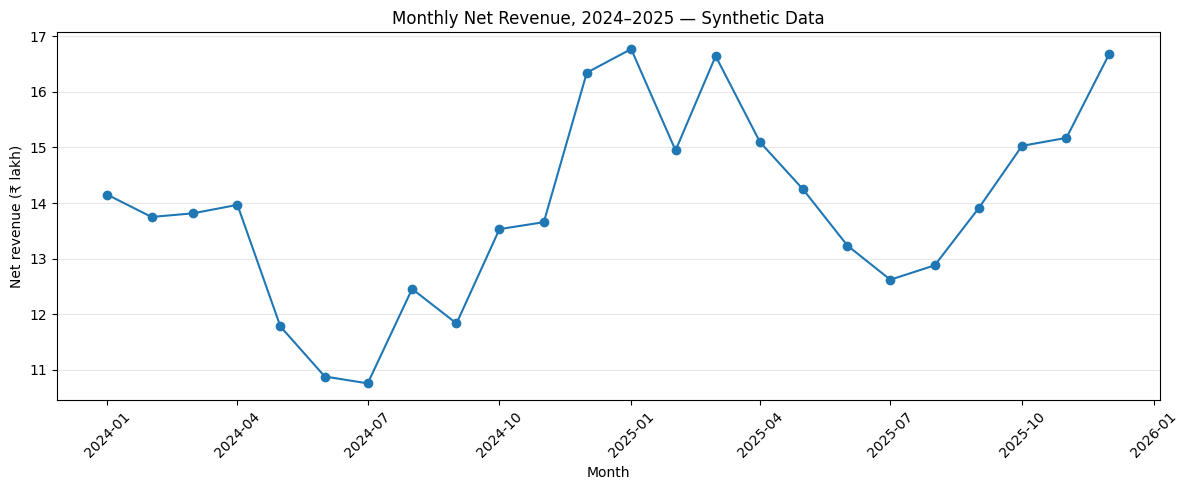

,month,packs_sold,net_revenue_inr
0,2024-01-01,21240,1415235.33
1,2024-02-01,20790,1374996.41
2,2024-03-01,20332,1381538.66
3,2024-04-01,20291,1396753.71
4,2024-05-01,18195,1177970.57
5,2024-06-01,16925,1087932.24
6,2024-07-01,16238,1075607.71
7,2024-08-01,18172,1245517.71
8,2024-09-01,18076,1183395.0
9,2024-10-01,19956,1353089.44


In [ ]:
import matplotlib.pyplot as plt

eda_sales["month"] = (
    eda_sales["sale_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_sales = (
    eda_sales.groupby("month")
    .agg(
        packs_sold=("quantity_packs", "sum"),
        revenue_paise=("net_revenue_paise", "sum")
    )
    .reset_index()
    .sort_values("month")
)

monthly_sales["net_revenue_inr"] = (
    monthly_sales["revenue_paise"] / 100
)

# Confirm the monthly totals match the yearly totals
assert (
    monthly_sales["revenue_paise"].sum()
    == yearly_summary["revenue_paise"].sum()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["month"],
    monthly_sales["net_revenue_inr"] / 100000,
    marker="o"
)

plt.title("Monthly Net Revenue, 2024–2025 — Synthetic Data")
plt.xlabel("Month")
plt.ylabel("Net revenue (₹ lakh)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_sales[[
    "month", "packs_sold", "net_revenue_inr"
]].round(2))

In [ ]:
highest_month = monthly_sales.loc[
    monthly_sales["net_revenue_inr"].idxmax()
]

lowest_month = monthly_sales.loc[
    monthly_sales["net_revenue_inr"].idxmin()
]

print(
    "Highest revenue month:",
    highest_month["month"].strftime("%B %Y"),
    f"— ₹{highest_month['net_revenue_inr']:,.2f}"
)

print(
    "Lowest revenue month:",
    lowest_month["month"].strftime("%B %Y"),
    f"— ₹{lowest_month['net_revenue_inr']:,.2f}"
)

print("Number of months:", len(monthly_sales))

Highest revenue month: January 2025 — ₹1,677,070.75
Lowest revenue month: July 2024 — ₹1,075,607.71
Number of months: 24


## 3. Category Sales Performance

,category_name,packs_sold,net_revenue_inr,revenue_share_pct
1,Anti-Infectives,53071,8305303.7,24.85
2,Cardiovascular,89944,6160126.24,18.43
4,Digestive Care,63706,4532777.82,13.56
5,Pain Relief,82815,3976336.33,11.9
0,Allergy Care,56346,3582137.16,10.72
3,Diabetes Care,67572,3058871.57,9.15
6,Respiratory,30648,2727006.85,8.16
7,Vitamins,44712,1074644.82,3.22


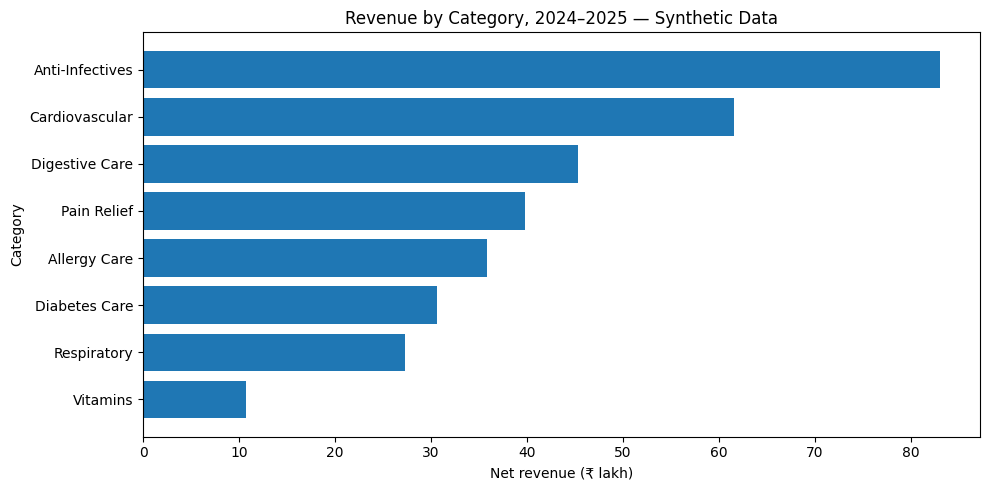

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
products = clean_tables["products"]
categories = clean_tables["categories"]

# Attach product categories to each sale
sales_with_category = eda_sales.merge(
    products[["product_id", "category_id"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

sales_with_category = sales_with_category.merge(
    categories[["category_id", "category_name"]],
    on="category_id",
    how="left",
    validate="many_to_one"
)

assert sales_with_category["category_name"].notna().all()
assert len(sales_with_category) == len(eda_sales)

# Summarise sales by category
category_sales = (
    sales_with_category.groupby("category_name")
    .agg(
        packs_sold=("quantity_packs", "sum"),
        revenue_paise=("net_revenue_paise", "sum")
    )
    .reset_index()
    .sort_values("revenue_paise", ascending=False)
)

assert (
    category_sales["revenue_paise"].sum()
    == eda_sales["net_revenue_paise"].sum()
)

category_sales["net_revenue_inr"] = (
    category_sales["revenue_paise"] / 100
)

category_sales["revenue_share_pct"] = (
    category_sales["revenue_paise"]
    / category_sales["revenue_paise"].sum() * 100
)

display(category_sales[[
    "category_name", "packs_sold",
    "net_revenue_inr", "revenue_share_pct"
]].round(2))

# Horizontal bars make category names easier to read
plot_data = category_sales.sort_values("revenue_paise")

plt.figure(figsize=(10, 5))
plt.barh(
    plot_data["category_name"],
    plot_data["net_revenue_inr"] / 100000
)
plt.xlabel("Net revenue (₹ lakh)")
plt.ylabel("Category")
plt.title("Revenue by Category, 2024–2025 — Synthetic Data")
plt.tight_layout()
plt.show()

## 4. Top 10 Products by Net Revenue

In [ ]:
# Summarise sales by product before attaching product names
product_sales = (
    eda_sales.groupby("product_id")
    .agg(
        packs_sold=("quantity_packs", "sum"),
        revenue_paise=("net_revenue_paise", "sum")
    )
    .reset_index()
)

product_sales = product_sales.merge(
    clean_tables["products"][["product_id", "product_name"]],
    on="product_id",
    how="left",
    validate="one_to_one"
)

assert product_sales["product_name"].notna().all()

assert (
    product_sales["revenue_paise"].sum()
    == eda_sales["net_revenue_paise"].sum()
)

product_sales["net_revenue_inr"] = (
    product_sales["revenue_paise"] / 100
)

product_sales["revenue_share_pct"] = (
    product_sales["revenue_paise"]
    / product_sales["revenue_paise"].sum() * 100
)

top_products = product_sales.sort_values(
    ["revenue_paise", "product_id"],
    ascending=[False, True]
).head(10)

display(top_products[[
    "product_id", "product_name", "packs_sold",
    "net_revenue_inr", "revenue_share_pct"
]].round(2))

print(
    "Top 10 products' share of total revenue:",
    f"{top_products['revenue_share_pct'].sum():.2f}%"
)

,product_id,product_name,packs_sold,net_revenue_inr,revenue_share_pct
57,P058,Azithromycin 250 mg Tablets - Pack of 20,9309,2485465.43,7.44
61,P062,Cefalexin 250 mg Capsules - Pack of 20,6485,1341263.08,4.01
95,P096,Fexofenadine 180 mg Tablets - Pack of 20,6808,1316994.57,3.94
29,P030,Atorvastatin 10 mg Tablets - Pack of 20,9411,1147064.99,3.43
79,P080,Naproxen 500 mg Tablets - Pack of 20,8563,1072450.8,3.21
17,P018,Esomeprazole 20 mg Tablets - Pack of 20,8116,927496.85,2.78
62,P063,Cefalexin 500 mg Capsules - Pack of 10,7418,896851.83,2.68
37,P038,Telmisartan 20 mg Tablets - Pack of 20,7198,885045.14,2.65
15,P016,Pantoprazole 40 mg Tablets - Pack of 20,8571,865390.78,2.59
53,P054,Amoxicillin 250 mg Capsules - Pack of 20,7951,808447.66,2.42


Top 10 products' share of total revenue: 35.15%


## 5. Sales by Customer Type

In [ ]:
# Attach customer details to sales
customer_sales = eda_sales.merge(
    clean_tables["customers"][[
        "customer_id", "customer_type", "city", "region"
    ]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

assert customer_sales["customer_type"].notna().all()
assert len(customer_sales) == len(eda_sales)

customer_type_summary = (
    customer_sales.groupby("customer_type")
    .agg(
        sales_lines=("sales_line_id", "count"),
        packs_sold=("quantity_packs", "sum"),
        revenue_paise=("net_revenue_paise", "sum")
    )
    .reset_index()
    .sort_values("revenue_paise", ascending=False)
)

assert (
    customer_type_summary["revenue_paise"].sum()
    == eda_sales["net_revenue_paise"].sum()
)

customer_type_summary["net_revenue_inr"] = (
    customer_type_summary["revenue_paise"] / 100
)

customer_type_summary["revenue_share_pct"] = (
    customer_type_summary["revenue_paise"]
    / customer_type_summary["revenue_paise"].sum() * 100
)

display(customer_type_summary[[
    "customer_type", "sales_lines", "packs_sold",
    "net_revenue_inr", "revenue_share_pct"
]].round(2))

,customer_type,sales_lines,packs_sold,net_revenue_inr,revenue_share_pct
2,Pharmacy,24773,244632,16704209.38,49.99
0,Clinic,12249,121231,8309609.57,24.87
1,Hospital,12250,121617,8295601.02,24.82
3,Unknown,161,1334,107784.52,0.32


## 6. Revenue per Active Customer by Customer Type

In [ ]:
# Exclude the Unknown placeholder from customer-count comparisons
identified_sales = customer_sales[
    customer_sales["customer_id"] != "C_UNKNOWN"
].copy()

customer_comparison = (
    identified_sales.groupby("customer_type")
    .agg(
        active_customers=("customer_id", "nunique"),
        revenue_paise=("net_revenue_paise", "sum")
    )
    .reset_index()
)

customer_comparison["net_revenue_inr"] = (
    customer_comparison["revenue_paise"] / 100
)

customer_comparison["revenue_per_active_customer_inr"] = (
    customer_comparison["net_revenue_inr"]
    / customer_comparison["active_customers"]
)

customer_comparison = customer_comparison.sort_values(
    "revenue_per_active_customer_inr",
    ascending=False
)

display(customer_comparison[[
    "customer_type",
    "active_customers",
    "net_revenue_inr",
    "revenue_per_active_customer_inr"
]].round(2))

,customer_type,active_customers,net_revenue_inr,revenue_per_active_customer_inr
2,Pharmacy,20,16704209.38,835210.47
0,Clinic,10,8309609.57,830960.96
1,Hospital,10,8295601.02,829560.1


## 7. Stock Availability as of 31 December 2025

In [ ]:
stock_snapshots = clean_tables["inventory_month_end"].copy()
products = clean_tables["products"].copy()

stock_snapshots["snapshot_date"] = pd.to_datetime(
    stock_snapshots["snapshot_date"],
    format="%Y-%m-%d",
    errors="raise"
)

stock_snapshots["closing_stock_packs"] = pd.to_numeric(
    stock_snapshots["closing_stock_packs"],
    errors="raise"
).astype("Int64")

products["reorder_point_packs"] = pd.to_numeric(
    products["reorder_point_packs"],
    errors="raise"
).astype("Int64")

report_date = pd.Timestamp("2025-12-31")

# Select one date: stock must not be added across months
current_stock = stock_snapshots[
    stock_snapshots["snapshot_date"] == report_date
].copy()

assert not current_stock.empty, "No snapshot found for the report date."

current_stock = current_stock.merge(
    products[[
        "product_id", "product_name", "reorder_point_packs"
    ]],
    on="product_id",
    how="left",
    validate="one_to_one"
)

assert current_stock["product_name"].notna().all()
assert set(current_stock["product_id"]) == set(products["product_id"])

current_stock["stock_status"] = "Above reorder point"

current_stock.loc[
    current_stock["closing_stock_packs"]
    <= current_stock["reorder_point_packs"],
    "stock_status"
] = "At or below reorder point"

current_stock.loc[
    current_stock["closing_stock_packs"] == 0,
    "stock_status"
] = "Out of stock"

stock_summary = (
    current_stock.groupby("stock_status")
    .agg(
        product_count=("product_id", "count"),
        stock_packs=("closing_stock_packs", "sum")
    )
    .reset_index()
)

print("Report date:", report_date.date())
print("Products checked:", len(current_stock))
print("Total stock packs:", current_stock["closing_stock_packs"].sum())

display(stock_summary)

Report date: 2025-12-31
Products checked: 100
Total stock packs: 23396


,stock_status,product_count,stock_packs
0,Above reorder point,96,23230
1,At or below reorder point,4,166


## 8. Low-Stock Products and Recent Sales

In [ ]:
# Use the final 90 calendar days, including the report date
window_start = report_date - pd.Timedelta(days=89)

recent_sales = eda_sales[
    eda_sales["sale_date"].between(window_start, report_date)
]

recent_product_sales = (
    recent_sales.groupby("product_id", as_index=False)
    .agg(packs_sold_90_days=("quantity_packs", "sum"))
)

stock_coverage = current_stock.merge(
    recent_product_sales,
    on="product_id",
    how="left",
    validate="one_to_one"
)

stock_coverage["packs_sold_90_days"] = (
    stock_coverage["packs_sold_90_days"]
    .fillna(0)
    .astype("Int64")
)

stock_coverage["average_daily_sales_packs"] = (
    stock_coverage["packs_sold_90_days"] / 90
)

# Coverage is undefined when there were no recent sales
daily_sales = stock_coverage[
    "average_daily_sales_packs"
].replace(0, pd.NA)

stock_coverage["estimated_days_of_stock"] = (
    stock_coverage["closing_stock_packs"] / daily_sales
)

low_stock_products = stock_coverage[
    stock_coverage["closing_stock_packs"]
    <= stock_coverage["reorder_point_packs"]
].sort_values("estimated_days_of_stock", na_position="last")

print("Recent sales period:",
      window_start.date(), "to", report_date.date())

display(low_stock_products[[
    "product_id",
    "product_name",
    "closing_stock_packs",
    "reorder_point_packs",
    "packs_sold_90_days",
    "estimated_days_of_stock"
]].round(2))

Recent sales period: 2025-10-03 to 2025-12-31


,product_id,product_name,closing_stock_packs,reorder_point_packs,packs_sold_90_days,estimated_days_of_stock
75,P076,Diclofenac 50 mg Tablets - Pack of 20,32,40,749,3.85
32,P033,Losartan 25 mg Tablets - Pack of 10,56,80,977,5.16
7,P008,Theophylline 200 mg Tablets - Pack of 20,38,40,375,9.12
93,P094,Fexofenadine 120 mg Tablets - Pack of 20,40,40,127,28.35


## 9. Batch Expiry Risk as of 31 December 2025

In [ ]:
# Restore the types needed for batch inventory analysis
batches = clean_tables["batches"].copy()
receipts = clean_tables["stock_receipts"].copy()
adjustments = clean_tables["stock_adjustments"].copy()

for column in ["manufacture_date", "expiry_date"]:
    batches[column] = pd.to_datetime(
        batches[column], format="%Y-%m-%d", errors="raise"
    )

batches["unit_cost_inr"] = pd.to_numeric(
    batches["unit_cost_inr"], errors="raise"
)

receipts["receipt_date"] = pd.to_datetime(
    receipts["receipt_date"], format="%Y-%m-%d", errors="raise"
)

adjustments["adjustment_date"] = pd.to_datetime(
    adjustments["adjustment_date"],
    format="%Y-%m-%d",
    errors="raise"
)

receipts["quantity_received_packs"] = pd.to_numeric(
    receipts["quantity_received_packs"], errors="raise"
).astype("Int64")

adjustments["quantity_change_packs"] = pd.to_numeric(
    adjustments["quantity_change_packs"], errors="raise"
).astype("Int64")

# Calculate batch stock using only records through the report date
received_by_batch = (
    receipts.loc[receipts["receipt_date"] <= report_date]
    .groupby("batch_id")["quantity_received_packs"].sum()
)

sold_by_batch = (
    eda_sales.loc[eda_sales["sale_date"] <= report_date]
    .groupby("batch_id")["quantity_packs"].sum()
)

adjusted_by_batch = (
    adjustments.loc[adjustments["adjustment_date"] <= report_date]
    .groupby("batch_id")["quantity_change_packs"].sum()
)

batch_stock = pd.concat([
    received_by_batch.rename("received"),
    sold_by_batch.rename("sold"),
    adjusted_by_batch.rename("adjusted")
], axis=1).fillna(0)

batch_stock["remaining_packs"] = (
    batch_stock["received"]
    - batch_stock["sold"]
    + batch_stock["adjusted"]
)

assert (batch_stock["remaining_packs"] >= 0).all()
assert (
    batch_stock["remaining_packs"].sum()
    == current_stock["closing_stock_packs"].sum()
)

batch_inventory = batch_stock.reset_index().merge(
    batches,
    on="batch_id",
    how="left",
    validate="one_to_one"
)

assert batch_inventory["expiry_date"].notna().all()
assert batch_inventory["unit_cost_inr"].notna().all()

# Only remaining stock is exposed to future expiry
batch_inventory = batch_inventory[
    batch_inventory["remaining_packs"] > 0
].copy()

batch_inventory["days_to_expiry"] = (
    batch_inventory["expiry_date"] - report_date
).dt.days

assert (batch_inventory["days_to_expiry"] > 0).all(), (
    "Expired stock remains; investigate before continuing."
)

# Value inventory at batch purchase cost
batch_inventory["unit_cost_paise"] = (
    batch_inventory["unit_cost_inr"] * 100
).round().astype("Int64")

batch_inventory["stock_value_paise"] = (
    batch_inventory["remaining_packs"].astype("Int64")
    * batch_inventory["unit_cost_paise"]
)

batch_inventory["expiry_window"] = pd.cut(
    batch_inventory["days_to_expiry"],
    bins=[0, 30, 60, 90, float("inf")],
    labels=["1–30 days", "31–60 days", "61–90 days", "Over 90 days"]
)

expiry_summary = (
    batch_inventory.groupby("expiry_window", observed=False)
    .agg(
        batches=("batch_id", "count"),
        remaining_packs=("remaining_packs", "sum"),
        stock_value_paise=("stock_value_paise", "sum")
    )
    .reset_index()
)

expiry_summary["stock_value_inr"] = (
    expiry_summary["stock_value_paise"] / 100
)

display(expiry_summary[[
    "expiry_window", "batches",
    "remaining_packs", "stock_value_inr"
]].round(2))

,expiry_window,batches,remaining_packs,stock_value_inr
0,1–30 days,3,295,32827.8
1,31–60 days,7,1412,115371.4
2,61–90 days,4,442,62955.28
3,Over 90 days,160,21247,1025043.32


## 10. Batches Requiring Expiry Review

In [ ]:
expiry_review = batch_inventory[
    batch_inventory["days_to_expiry"] <= 90
].copy()

expiry_review = expiry_review.merge(
    clean_tables["products"][["product_id", "product_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

assert expiry_review["product_name"].notna().all()

expiry_review["stock_value_inr"] = (
    expiry_review["stock_value_paise"] / 100
)

# Earliest expiry first; higher value first when expiry dates match
expiry_review = expiry_review.sort_values(
    ["days_to_expiry", "stock_value_paise"],
    ascending=[True, False]
)

display(expiry_review[[
    "batch_id",
    "product_name",
    "expiry_date",
    "days_to_expiry",
    "remaining_packs",
    "stock_value_inr"
]].round(2))

print("Batches requiring review:", len(expiry_review))

,batch_id,product_name,expiry_date,days_to_expiry,remaining_packs,stock_value_inr
2,B001726,Amoxicillin 500 mg Capsules - Pack of 20,2026-01-07,7,73,7340.88
4,B001787,Cefalexin 250 mg Capsules - Pack of 20,2026-01-13,13,168,23829.12
6,B001801,Glimepiride 2 mg Tablets - Pack of 10,2026-01-26,26,54,1657.8
3,B001776,Esomeprazole 40 mg Tablets - Pack of 20,2026-02-03,34,210,22614.9
13,B001876,Cefalexin 500 mg Capsules - Pack of 10,2026-02-04,35,267,23808.39
7,B001812,Amoxicillin 250 mg Capsules - Pack of 20,2026-02-11,42,270,21259.8
11,B001834,Fexofenadine 120 mg Tablets - Pack of 10,2026-02-18,49,183,11247.18
9,B001827,Azithromycin 250 mg Tablets - Pack of 20,2026-02-20,51,105,24242.4
5,B001798,Cyanocobalamin 1 mg Tablets - Pack of 10,2026-02-21,52,294,5456.64
10,B001832,Losartan 50 mg Tablets - Pack of 20,2026-02-24,55,83,6742.09


Batches requiring review: 14


## 11. Findings and Recommendations

- Net revenue increased by approximately 13.0% in 2025,
  while packs sold increased by 7.4%.
- The top 10 products contributed 35.15% of total revenue.
- Revenue per active customer was similar across customer types.
- Four products were at or below their reorder points.
  P076 and P033 had the lowest estimated stock coverage.
- Fourteen batches, valued at ₹2,11,154.48, were due to expire
  within 90 days of 31 December 2025.
- Review the earliest-expiring batches first, monitor sales against
  remaining quantities, and consider expiry exposure before purchasing.

These findings describe synthetic data. Stock coverage uses historical
sales rather than a demand forecast. Expiry exposure is not a confirmed loss.

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import shutil
from google.colab import files

eda_folder = Path("/content/pharma_eda_checkpoint")
tables_folder = eda_folder / "tables"
charts_folder = eda_folder / "charts"

tables_folder.mkdir(parents=True, exist_ok=True)
charts_folder.mkdir(parents=True, exist_ok=True)

eda_outputs = {
    "yearly_sales": yearly_summary,
    "monthly_sales": monthly_sales,
    "category_sales": category_sales,
    "product_sales": product_sales,
    "top_10_products": top_products,
    "customer_type_sales": customer_type_summary,
    "revenue_per_active_customer": customer_comparison,
    "stock_as_of_2025_12_31": current_stock,
    "stock_coverage": stock_coverage,
    "low_stock_products": low_stock_products,
    "expiry_summary": expiry_summary,
    "expiry_review": expiry_review
}

for name, table in eda_outputs.items():
    table.to_csv(
        tables_folder / f"{name}.csv",
        index=False,
        date_format="%Y-%m-%d"
    )

# Monthly revenue chart
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    monthly_sales["month"],
    monthly_sales["net_revenue_inr"] / 100000,
    marker="o"
)
ax.set_title("Monthly Net Revenue — Synthetic Data")
ax.set_xlabel("Month")
ax.set_ylabel("Net revenue (INR lakh)")
ax.grid(axis="y", alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(charts_folder / "monthly_revenue.png", dpi=200)
plt.close(fig)

# Category revenue chart
category_plot = category_sales.sort_values("revenue_paise")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(
    category_plot["category_name"],
    category_plot["net_revenue_inr"] / 100000
)
ax.set_title("Revenue by Category — Synthetic Data")
ax.set_xlabel("Net revenue (INR lakh)")
fig.tight_layout()
fig.savefig(charts_folder / "category_revenue.png", dpi=200)
plt.close(fig)

# Top-product revenue chart
product_plot = top_products.sort_values("revenue_paise")

fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(
    product_plot["product_name"],
    product_plot["net_revenue_inr"] / 100000
)
ax.set_title("Top 10 Products by Revenue — Synthetic Data")
ax.set_xlabel("Net revenue (INR lakh)")
fig.tight_layout()
fig.savefig(charts_folder / "top_10_products.png", dpi=200)
plt.close(fig)

(eda_folder / "README.txt").write_text(
    "Synthetic pharmaceutical distributor analysis, 2024–2025.\n"
    "Inventory reporting date: 31 December 2025.\n"
    "Money columns ending in _paise are integer paise; "
    "columns ending in _inr are rupees.\n"
    "Expiry value is potential exposure, not confirmed loss.\n"
    "Keep the separate cleaning checkpoint and Colab notebook.\n"
)

zip_path = shutil.make_archive(
    "/content/Pharma_EDA_Checkpoint",
    "zip",
    root_dir=eda_folder
)

print("Saved 12 EDA tables and 3 charts.")
files.download(zip_path)

Saved 12 EDA tables and 3 charts.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Your notes

Write: (1) the size of each table, (2) the quality issues you observed, (3) which checks you want to run next.

Next session: make working copies, define cleaning rules, clean and validate, then export to cleaned_data. No dashboard or business result is complete yet.
